In [3]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("C:/Users/MARLON_/Downloads/superstore_sales.csv")

print(df.shape)
print(df.head())
print(df.info())


(10800, 21)
  Row ID        Order ID  Order Date   Ship Date       Ship Mode Customer ID  \
0      1  CA-2017-152156   11/8/2017  11/11/2017    Second Class    CG-12520   
1      2  CA-2017-152156   11/8/2017  11/11/2017    Second Class    CG-12520   
2      3  CA-2017-138688   6/12/2017   6/16/2017    Second Class    DV-13045   
3      4  US-2016-108966  10/11/2016  10/18/2016  Standard Class    SO-20335   
4      5  US-2016-108966  10/11/2016  10/18/2016  Standard Class    SO-20335   

     Customer Name    Segment        Country             City  ...  \
0      Claire Gute   Consumer  United States        Henderson  ...   
1      Claire Gute   Consumer  United States        Henderson  ...   
2  Darrin Van Huff  Corporate  United States      Los Angeles  ...   
3   Sean O'Donnell   Consumer  United States  Fort Lauderdale  ...   
4   Sean O'Donnell   Consumer  United States  Fort Lauderdale  ...   

  Postal Code  Region       Product ID         Category Sub-Category  \
0     42420.0 

In [4]:

# Check missing values
print(df.isnull().sum())

# Remove incomplete sales records
df = df.dropna(subset=[
    "Order Date", "Sales", "Profit",
    "Quantity", "Discount", "Category",
    "Region", "Segment", "Customer ID"
]).copy()

# Convert dates
df["Order Date"] = pd.to_datetime(
    df["Order Date"], format="%m/%d/%Y"
)

# Extract time information
df["Year"] = df["Order Date"].dt.year
df["Month"] = df["Order Date"].dt.month
df["Year-Month"] = df["Order Date"].dt.to_period("M")

# Remove duplicates only if truly identical
df = df.drop_duplicates()

print("Cleaned records:", len(df))


Row ID             0
Order ID           0
Order Date       806
Ship Date        806
Ship Mode        806
Customer ID      806
Customer Name    806
Segment          806
Country          806
City             806
State            806
Postal Code      817
Region           806
Product ID       806
Category         806
Sub-Category     806
Product Name     806
Sales            806
Quantity         806
Discount         806
Profit           806
dtype: int64
Cleaned records: 9994


In [5]:

customer = df.groupby("Customer ID").agg(
    Total_Sales=("Sales", "sum"),
    Total_Quantity=("Quantity", "sum"),
    Total_Orders=("Order ID", "nunique")
).sort_values("Total_Sales", ascending=False)

print(customer.head(10))

print("Unique customers:", df["Customer ID"].nunique())
print("Total orders:", df["Order ID"].nunique())
print("Items sold:", df["Quantity"].sum())


             Total_Sales  Total_Quantity  Total_Orders
Customer ID                                           
SM-20320       25043.050            50.0             5
TC-20980       19052.218            42.0             5
RB-19360       15117.339            71.0             6
TA-21385       14595.620            36.0             4
AB-10105       14473.571            73.0            10
KL-16645       14175.229           113.0            12
SC-20095       14142.334            87.0             9
HL-15040       12873.298            50.0             6
SE-20110       12209.438            78.0            11
CC-12370       12129.072            34.0             5
Unique customers: 793
Total orders: 5009
Items sold: 37873.0


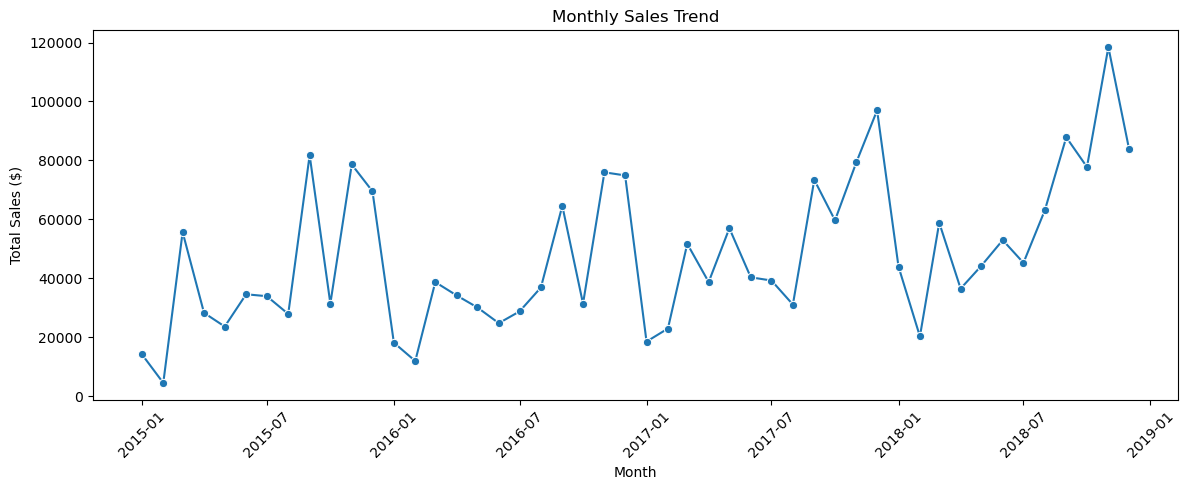

In [6]:

monthly = df.groupby("Year-Month")["Sales"].sum()

monthly.index = monthly.index.to_timestamp()

plt.figure(figsize=(12, 5))
sns.lineplot(x=monthly.index, y=monthly.values,
             marker="o")

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales ($)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


                     Sales     Profit
Category                             
Furniture        741999.80   18451.27
Office Supplies  719047.03  122490.80
Technology       836154.03  145454.95


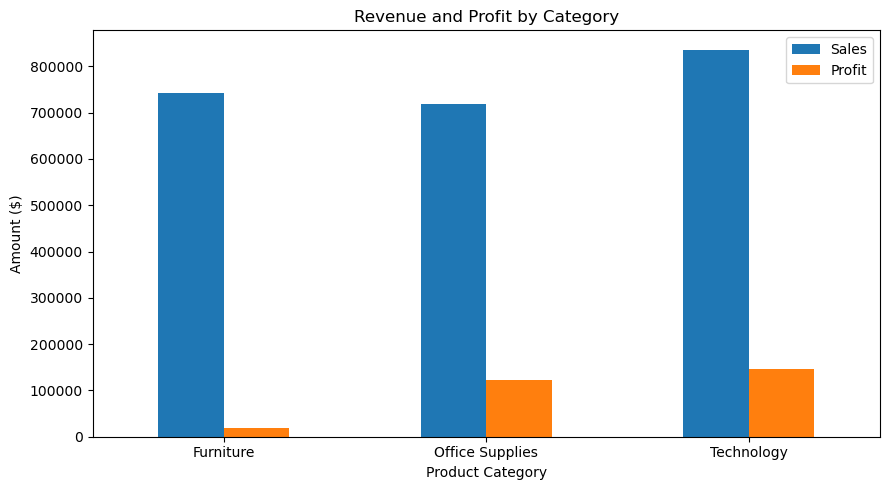

In [7]:

category = df.groupby("Category")[["Sales", "Profit"]].sum()

print(category.round(2))

category.plot(kind="bar", figsize=(9, 5))

plt.title("Revenue and Profit by Category")
plt.xlabel("Product Category")
plt.ylabel("Amount ($)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


Regional performance:
             Sales     Profit
Region                       
Central  501239.89   39706.36
East     678781.24   91522.78
South    391721.90   46749.43
West     725457.82  108418.45

Customer segments:
                  Sales     Profit
Segment                           
Consumer     1161401.34  134119.21
Corporate     706146.37   91979.13
Home Office   429653.15   60298.68


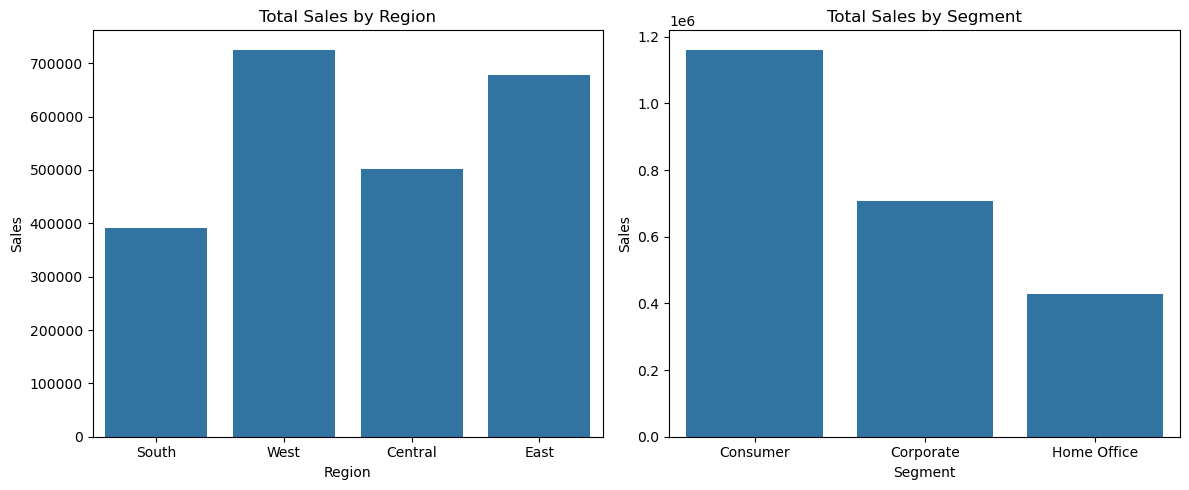

In [8]:

region = df.groupby("Region")[["Sales", "Profit"]].sum()
segment = df.groupby("Segment")[["Sales", "Profit"]].sum()

print("Regional performance:")
print(region.round(2))

print("\nCustomer segments:")
print(segment.round(2))

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.barplot(data=df, x="Region", y="Sales",
            estimator=sum, errorbar=None, ax=axes[0])
axes[0].set_title("Total Sales by Region")

sns.barplot(data=df, x="Segment", y="Sales",
            estimator=sum, errorbar=None, ax=axes[1])
axes[1].set_title("Total Sales by Segment")

plt.tight_layout()
plt.show()


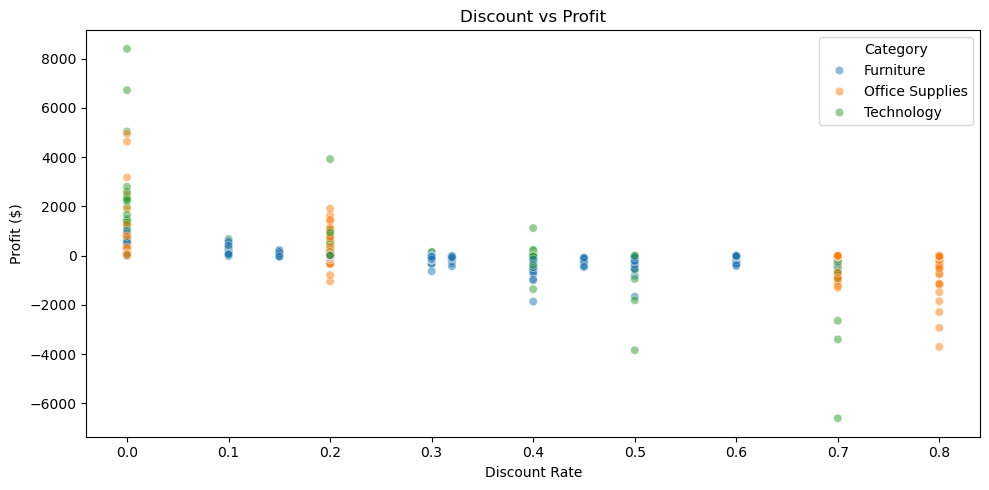

          Total_Sales  Total_Profit  Profit_Margin
Discount                                          
0.00       1087908.47     320987.60          29.51
0.10         54369.35       9029.18          16.61
0.15         27558.52       1418.99           5.15
0.20        764594.37      90337.31          11.82
0.30        103226.66     -10369.28         -10.05
0.32         14493.46      -2391.14         -16.50
0.40        116417.78     -23057.05         -19.81
0.45          5484.97      -2493.11         -45.45
0.50         58918.54     -20506.43         -34.80
0.60          6644.70      -5944.66         -89.46
0.70         40620.28     -40075.36         -98.66
0.80         16963.76     -30539.04        -180.03


In [9]:

plt.figure(figsize=(10, 5))

sns.scatterplot(
    data=df,
    x="Discount",
    y="Profit",
    hue="Category",
    alpha=0.5
)

plt.title("Discount vs Profit")
plt.xlabel("Discount Rate")
plt.ylabel("Profit ($)")
plt.tight_layout()
plt.show()

# Profit at different discount levels
discount_analysis = df.groupby("Discount").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum")
)

discount_analysis["Profit_Margin"] = (
    discount_analysis["Total_Profit"] /
    discount_analysis["Total_Sales"] * 100
)

print(discount_analysis.round(2))


The Superstore Sales analysis included number of customers, monthly sales trends, category sales by product, sales revenue by region, customer segments and discount sensitivity.
From the results, it is shown that Technology is the most significant category in terms of both revenue and profit and Furniture, in combination, is the most generating revenue but has lower profit margin. In addition, sales are seasonal, with November having the highest total revenue over the period.
West is the most robust area in sales and profit, and it is the Consumer segment that generates the majority of sales. Interestingly, the more the company discounted items, the less profit it made; so the company needs to assess its discounting practices.
All in all, Furniture business should better Furniture profitability, get ready for periodic market, Keep good clients, and add discount rule more strictly.